<a href="https://colab.research.google.com/github/arjunk-15/RetailMart-Sales-Inventory-Analytics/blob/main/RetailMart_Data_Cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Data Cleaning using Python and Pandas in Google Colab.**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Load all five datasets

In [ ]:

sales = pd.read_csv("Sales_Transactions.csv")
products = pd.read_csv("Products.csv")
stores = pd.read_csv("Stores.csv")
customers = pd.read_csv("Customers.csv")
inventory = pd.read_csv("Inventory_History.csv")

print("Sales:", sales.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("Customers:", customers.shape)
print("Inventory:", inventory.shape)

Sales: (10000, 12)
Products: (60, 6)
Stores: (6, 4)
Customers: (3000, 3)
Inventory: (75680, 9)


In [ ]:
sales.head()
sales.info()
sales.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Transaction_ID     10000 non-null  object 
 1   Order_ID           10000 non-null  object 
 2   Order_Date         10000 non-null  object 
 3   Product_ID         10000 non-null  object 
 4   Store_ID           10000 non-null  object 
 5   Customer_ID        9925 non-null   object 
 6   Quantity           10000 non-null  float64
 7   Unit_Price         10000 non-null  object 
 8   Discount_Pct       9965 non-null   float64
 9   Return_Quantity    10000 non-null  int64  
 10  Unit_Cost_At_Sale  10000 non-null  object 
 11  Payment_Method     9955 non-null   object 
dtypes: float64(2), int64(1), object(9)
memory usage: 937.6+ KB


,0
Transaction_ID,0
Order_ID,0
Order_Date,0
Product_ID,0
Store_ID,0
Customer_ID,75
Quantity,0
Unit_Price,0
Discount_Pct,35
Return_Quantity,0


Remove duplicate transactions

In [ ]:
print("Full duplicate rows:", sales.duplicated().sum())

print("Duplicate Transaction IDs:",
      sales["Transaction_ID"].duplicated().sum())

sales[sales["Transaction_ID"].duplicated(keep=False)]

Full duplicate rows: 12
Duplicate Transaction IDs: 12


,Transaction_ID,Order_ID,Order_Date,Product_ID,Store_ID,Customer_ID,Quantity,Unit_Price,Discount_Pct,Return_Quantity,Unit_Cost_At_Sale,Payment_Method
616,T000617,O000488,21-02-2024,P022,S03,C00741,3.0,? 388.25,0.0,0,? 202.93,UPI
1062,T001063,O000843,29-03-2024,P022,S03,C00916,2.0,? 388.25,15.0,0,? 202.93,Card
1594,T001595,O001278,12-05-2024,P022,S05,C02986,3.0,? 388.25,0.0,0,? 202.93,UPI
1609,T001610,O001290,13-05-2024,P055,S03,C00178,1.0,? 404.42,0.0,0,? 254.85,Cash
2067,T002068,O001648,14-06-2024,P031,S01,C00925,2.0,"? 1,436.05",10.0,0,? 875.14,Cash
2127,T002128,O001691,19-06-2024,P038,S04,C00949,1.0,? 685.65,5.0,0,? 369.78,UPI
2204,T002205,O001750,24-06-2024,P011,S05,C02946,1.0,"? 2,644.48",15.0,0,"? 1,930.50",UPI
2713,T002714,O002164,06-08-2024,P055,S05,C00531,2.0,? 404.42,15.0,0,? 254.85,Cash
3558,T003559,O002842,11-10-2024,P056,S01,C00029,1.0,"? 2,298.69",0.0,0,"? 1,415.02",UPI
3564,T003565,O002847,12-10-2024,P011,S05,C01020,2.0,"? 2,644.48",5.0,0,"? 1,930.50",Card


Handling Missing Values

In [ ]:
sales_clean = sales.copy()
sales_clean = sales_clean.drop_duplicates()
sales_clean = sales_clean.reset_index(drop=True)

print("Original records:", len(sales))
print("Cleaned records:", len(sales_clean))
print("Duplicates remaining:", sales_clean.duplicated().sum())
print("Duplicate Transaction IDs:", sales_clean["Transaction_ID"].duplicated().sum())

Original records: 10000
Cleaned records: 9988
Duplicates remaining: 0
Duplicate Transaction IDs: 0


In [ ]:
sales_clean.isnull().sum()
sales_clean[sales_clean.isnull().any(axis=1)].head(10)

,Transaction_ID,Order_ID,Order_Date,Product_ID,Store_ID,Customer_ID,Quantity,Unit_Price,Discount_Pct,Return_Quantity,Unit_Cost_At_Sale,Payment_Method
27,T000028,O000023,03-01-2024,P033,S02,NaN,2.0,? 576.65,0.0,0,? 355.15,UPI
37,T000038,O000032,04-01-2024,P019,S03,NaN,1.0,"? 1,017.64",0.0,0,? 569.89,Card
41,T000042,O000036,04-01-2024,P035,S06,NaN,2.0,"? 1,097.64",25.0,0,? 856.18,Card
116,T000117,O000099,11-01-2024,P004,S02,NaN,1.0,"? 7,630.40",0.0,1,"? 5,131.22",UPI
144,T000145,O000123,14-01-2024,P030,S03,C02199,1.0,"? 2,256.01",0.0,0,"? 1,389.19",NaN
157,T000158,O000132,15-01-2024,P053,S06,C00365,2.0,"? 2,089.23",NaN,0,"? 1,207.65",UPI
242,T000243,O000200,23-01-2024,P010,S03,C00445,1.0,"? 1,414.85",NaN,0,? 731.29,UPI
309,T000310,O000251,29-01-2024,P014,S01,C02438,1.0,"? 1,923.41",0.0,0,? 936.23,NaN
556,T000557,O000440,16-02-2024,P055,S06,NaN,2.0,? 404.42,10.0,0,? 254.85,UPI
577,T000578,O000457,18-02-2024,P033,S04,C02857,1.0,? 576.65,0.0,0,? 355.15,NaN


In [ ]:
sales_clean.isnull().sum()
sales_clean.isnull().sum()
sales_clean[sales_clean.isnull().any(axis=1)].head(10)

,Transaction_ID,Order_ID,Order_Date,Product_ID,Store_ID,Customer_ID,Quantity,Unit_Price,Discount_Pct,Return_Quantity,Unit_Cost_At_Sale,Payment_Method
27,T000028,O000023,03-01-2024,P033,S02,NaN,2.0,? 576.65,0.0,0,? 355.15,UPI
37,T000038,O000032,04-01-2024,P019,S03,NaN,1.0,"? 1,017.64",0.0,0,? 569.89,Card
41,T000042,O000036,04-01-2024,P035,S06,NaN,2.0,"? 1,097.64",25.0,0,? 856.18,Card
116,T000117,O000099,11-01-2024,P004,S02,NaN,1.0,"? 7,630.40",0.0,1,"? 5,131.22",UPI
144,T000145,O000123,14-01-2024,P030,S03,C02199,1.0,"? 2,256.01",0.0,0,"? 1,389.19",NaN
157,T000158,O000132,15-01-2024,P053,S06,C00365,2.0,"? 2,089.23",NaN,0,"? 1,207.65",UPI
242,T000243,O000200,23-01-2024,P010,S03,C00445,1.0,"? 1,414.85",NaN,0,? 731.29,UPI
309,T000310,O000251,29-01-2024,P014,S01,C02438,1.0,"? 1,923.41",0.0,0,? 936.23,NaN
556,T000557,O000440,16-02-2024,P055,S06,NaN,2.0,? 404.42,10.0,0,? 254.85,UPI
577,T000578,O000457,18-02-2024,P033,S04,C02857,1.0,? 576.65,0.0,0,? 355.15,NaN


Handle Customer IDs and Payment Methods using
*'UNKNOWN'*

In [ ]:
sales_clean["Customer_ID"] = sales_clean["Customer_ID"].fillna("UNKNOWN")
sales_clean["Payment_Method"] = sales_clean["Payment_Method"].fillna("Unknown")

print(sales_clean[["Customer_ID", "Payment_Method"]].isnull().sum())

Customer_ID       0
Payment_Method    0
dtype: int64


In [ ]:
print("Missing discounts:", sales_clean["Discount_Pct"].isnull().sum())
print("Invalid discounts:", ((sales_clean["Discount_Pct"] < 0) | (sales_clean["Discount_Pct"] > 100)).sum())

print("Discount values:")
print(sales_clean["Discount_Pct"].value_counts(dropna=False).sort_index())

Missing discounts: 35
Invalid discounts: 12
Discount values:
Discount_Pct
0.0      4224
5.0      2344
10.0     1647
15.0      958
20.0      525
25.0      224
30.0       19
110.0      12
NaN        35
Name: count, dtype: int64


In [ ]:
sales_clean.loc[
    (sales_clean["Discount_Pct"] < 0) |
    (sales_clean["Discount_Pct"] > 100),
    "Discount_Pct"
] = np.nan

print("Missing discounts:", sales_clean["Discount_Pct"].isnull().sum())
print("Invalid discounts:", ((sales_clean["Discount_Pct"] < 0) | (sales_clean["Discount_Pct"] > 100)).sum())

Missing discounts: 47
Invalid discounts: 0


In [ ]:
sales_clean["Order_Date"] = pd.to_datetime(
    sales_clean["Order_Date"],
    dayfirst=True,
    errors="coerce"
)

for col in ["Unit_Price", "Unit_Cost_At_Sale"]:
    sales_clean[col] = pd.to_numeric(
        sales_clean[col].astype(str).str.replace(r"[^\d.-]", "", regex=True),
        errors="coerce"
    )

print(sales_clean[["Order_Date", "Unit_Price", "Unit_Cost_At_Sale"]].dtypes)
print(sales_clean[["Order_Date", "Unit_Price", "Unit_Cost_At_Sale"]].isnull().sum())

Order_Date           datetime64[ns]
Unit_Price                  float64
Unit_Cost_At_Sale           float64
dtype: object
Order_Date           0
Unit_Price           0
Unit_Cost_At_Sale    0
dtype: int64


Validate Dates and Quantities

In [ ]:
print("Earliest date:", sales_clean["Order_Date"].min())
print("Latest date:", sales_clean["Order_Date"].max())

print("Dates outside reporting period:", (
    ~sales_clean["Order_Date"].between("2024-01-01", "2025-12-31")
).sum())

print("Invalid quantities:", (
    (sales_clean["Quantity"] <= 0) |
    (sales_clean["Quantity"] % 1 != 0)
).sum())

print(sales_clean["Quantity"].value_counts().sort_index())

Earliest date: 2024-01-01 00:00:00
Latest date: 2025-12-31 00:00:00
Dates outside reporting period: 0
Invalid quantities: 18
Quantity
0.0      18
1.0    6412
2.0    2470
3.0     882
4.0     206
Name: count, dtype: int64


In [ ]:
invalid_sales = sales_clean[
    (sales_clean["Quantity"] <= 0) |
    (sales_clean["Quantity"] % 1 != 0)
].copy()

sales_clean = sales_clean[
    (sales_clean["Quantity"] > 0) &
    (sales_clean["Quantity"] % 1 == 0)
].copy()

sales_clean["Quantity"] = sales_clean["Quantity"].astype(int)
sales_clean = sales_clean.reset_index(drop=True)

print("Invalid quantity records:", len(invalid_sales))
print("Remaining sales records:", len(sales_clean))
print("Invalid quantities remaining:", (sales_clean["Quantity"] <= 0).sum())

Invalid quantity records: 18
Remaining sales records: 9970
Invalid quantities remaining: 0


In [ ]:
for col in ["Store_ID", "Product_ID"]:
    sales_clean[col] = sales_clean[col].astype(str).str.strip().str.upper()

print("Unique Store IDs:", sales_clean["Store_ID"].nunique())
print("Unique Product IDs:", sales_clean["Product_ID"].nunique())

print("Store IDs:", sorted(sales_clean["Store_ID"].unique()))
print("Remaining records:", len(sales_clean))

Unique Store IDs: 6
Unique Product IDs: 60
Store IDs: ['S01', 'S02', 'S03', 'S04', 'S05', 'S06']
Remaining records: 9970


Final Sales Validation

In [ ]:
print("Invalid unit prices:", (
    sales_clean["Unit_Price"] <= 0
).sum())

print("Invalid unit costs:", (
    sales_clean["Unit_Cost_At_Sale"] < 0
).sum())

print("Invalid return quantities:", (
    (sales_clean["Return_Quantity"] < 0) |
    (sales_clean["Return_Quantity"] > sales_clean["Quantity"])
).sum())

print("Missing discounts:",
      sales_clean["Discount_Pct"].isna().sum())

print("Dates changed during conversion:", (
    sales_clean["Order_Date"].dt.strftime("%d-%m-%Y") !=
    pd.to_datetime(
        sales.loc[
            sales["Transaction_ID"].isin(sales_clean["Transaction_ID"]),
            "Order_Date"
        ],
        dayfirst=True,
        errors="coerce"
    ).dt.strftime("%d-%m-%Y").values
).sum() if len(sales_clean) == len(
    sales.loc[sales["Transaction_ID"].isin(sales_clean["Transaction_ID"])]
) else "Requires ID-based comparison")

Invalid unit prices: 0
Invalid unit costs: 0
Invalid return quantities: 0
Missing discounts: 47
Dates changed during conversion: Requires ID-based comparison


In [ ]:
original_dates = sales.drop_duplicates("Transaction_ID").set_index("Transaction_ID")["Order_Date"]

original_dates = pd.to_datetime(
    original_dates,
    format="%d-%m-%Y",
    errors="coerce"
)

comparison = sales_clean[["Transaction_ID", "Order_Date"]].copy()
comparison["Original_Date"] = comparison["Transaction_ID"].map(original_dates)

print("Unparsed original dates:", comparison["Original_Date"].isna().sum())
print("Date mismatches:", (
    comparison["Order_Date"] != comparison["Original_Date"]
).sum())

print("Remaining records:", len(sales_clean))

Unparsed original dates: 0
Date mismatches: 0
Remaining records: 9970


**Clean the remaining four datasets**

We'll handle *Products, Stores, Customers,* and *Inventory_History* together.

In [ ]:
datasets = {
    "Products": products,
    "Stores": stores,
    "Customers": customers,
    "Inventory": inventory
}

cleaned_datasets = {}

for name, df in datasets.items():
    cleaned = df.copy()
    cleaned.columns = cleaned.columns.str.strip()
    cleaned = cleaned.drop_duplicates().reset_index(drop=True)

    for col in cleaned.select_dtypes(include="object").columns:
        cleaned[col] = cleaned[col].astype("string").str.strip()

    cleaned_datasets[name] = cleaned

    print(f"\n{name}")
    print("Original records:", len(df))
    print("Remaining records:", len(cleaned))
    print("Duplicates removed:", len(df) - len(cleaned))
    print("Missing values:")
    print(cleaned.isnull().sum().to_string())

products_clean = cleaned_datasets["Products"]
stores_clean = cleaned_datasets["Stores"]
customers_clean = cleaned_datasets["Customers"]
inventory_clean = cleaned_datasets["Inventory"]


Products
Original records: 60
Remaining records: 60
Duplicates removed: 0
Missing values:
Product_ID        0
Product_Name      0
Category          0
List_Price        0
Unit_Cost         0
Product_Status    0

Stores
Original records: 6
Remaining records: 6
Duplicates removed: 0
Missing values:
Store_ID      0
Store_Name    0
City          0
Region        0

Customers
Original records: 3000
Remaining records: 3000
Duplicates removed: 0
Missing values:
Customer_ID          0
Customer_Segment    30
Join_Date            0

Inventory
Original records: 75680
Remaining records: 75680
Duplicates removed: 0
Missing values:
Date                 0
Store_ID             1
Product_ID           1
Opening_Stock        1
Stock_Received      29
Units_Sold           1
Stock_Adjustment     1
Closing_Stock        1
Unit_Cost            1


*Closing Stock = Opening Stock + Stock Received - Units Sold + Stock Adjustment*

In [ ]:
customers_clean["Customer_Segment"] = customers_clean["Customer_Segment"].fillna("Unknown")

customers_clean["Join_Date"] = pd.to_datetime(
    customers_clean["Join_Date"],
    errors="coerce",
    dayfirst=True
)

print("Customer missing values:")
print(customers_clean.isnull().sum())

print("\nInventory rows with missing values:")
display(inventory_clean[inventory_clean.isna().any(axis=1)].head(15))

print("\nInventory data types:")
print(inventory_clean.dtypes)

print("\nInventory date range:")
print(inventory_clean["Date"].min(), inventory_clean["Date"].max())

Customer missing values:
Customer_ID         0
Customer_Segment    0
Join_Date           0
dtype: int64

Inventory rows with missing values:


/tmp/ipykernel_507/95695810.py:3: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  customers_clean["Join_Date"] = pd.to_datetime(


,Date,Store_ID,Product_ID,Opening_Stock,Stock_Received,Units_Sold,Stock_Adjustment,Closing_Stock,Unit_Cost
3196,2024-09-29,S01,P005,18.0,NaN,0.0,0.0,18.0,1176.85
3912,2024-09-14,S01,P006,83.0,NaN,0.0,0.0,83.0,1084.46
3982,2024-11-23,S01,P006,95.0,NaN,0.0,0.0,95.0,1084.46
5281,2024-06-13,S01,P008,54.0,NaN,0.0,0.0,54.0,5322.32
10807,2025-07-27,S01,P015,108.0,NaN,0.0,0.0,108.0,482.98
11547,2025-08-05,S01,P016,85.0,NaN,0.0,0.0,85.0,83.19
14277,2025-01-23,S01,P020,49.0,NaN,0.0,0.0,49.0,1172.97
16555,2025-04-18,S01,P023,85.0,NaN,0.0,0.0,85.0,237.47
17133,2024-11-16,S01,P024,27.0,NaN,0.0,0.0,27.0,1165.41
17843,2024-10-26,S01,P025,45.0,NaN,0.0,0.0,45.0,230.02



Inventory data types:
Date                string[python]
Store_ID            string[python]
Product_ID          string[python]
Opening_Stock              float64
Stock_Received             float64
Units_Sold                 float64
Stock_Adjustment           float64
Closing_Stock              float64
Unit_Cost                  float64
dtype: object

Inventory date range:
2024-01-01 2025-12-31


In [ ]:

inventory_clean["Date"] = pd.to_datetime(
    inventory_clean["Date"], format="%Y-%m-%d", errors="coerce"
)

for col in ["Store_ID", "Product_ID"]:
    inventory_clean[col] = inventory_clean[col].str.upper().str.strip()

missing_receipts = inventory_clean["Stock_Received"].isna()

calculated_receipts = (
    inventory_clean["Closing_Stock"]
    - inventory_clean["Opening_Stock"]
    + inventory_clean["Units_Sold"]
    - inventory_clean["Stock_Adjustment"]
)

recoverable = missing_receipts & calculated_receipts.notna() & (calculated_receipts >= 0)

inventory_clean.loc[recoverable, "Stock_Received"] = calculated_receipts[recoverable]

print("Recovered stock receipts:", recoverable.sum())
print("Missing values remaining:")
print(inventory_clean.isna().sum())

balance_difference = (
    inventory_clean["Opening_Stock"]
    + inventory_clean["Stock_Received"]
    - inventory_clean["Units_Sold"]
    + inventory_clean["Stock_Adjustment"]
    - inventory_clean["Closing_Stock"]
)

print("Stock balance mismatches:", (balance_difference.abs() > 0.000001).sum())

print("Rows with incomplete inventory data:")
display(inventory_clean[inventory_clean.isna().any(axis=1)])


Recovered stock receipts: 28
Missing values remaining:
Date                1
Store_ID            1
Product_ID          1
Opening_Stock       1
Stock_Received      1
Units_Sold          1
Stock_Adjustment    1
Closing_Stock       1
Unit_Cost           1
dtype: int64
Stock balance mismatches: 23
Rows with incomplete inventory data:


,Date,Store_ID,Product_ID,Opening_Stock,Stock_Received,Units_Sold,Stock_Adjustment,Closing_Stock,Unit_Cost
75679,NaT,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN


**Final Inventory Cleaning**

In [ ]:

inventory_clean = inventory_clean.dropna(how="all").copy()

inventory_clean["Expected_Closing_Stock"] = (
    inventory_clean["Opening_Stock"]
    + inventory_clean["Stock_Received"]
    - inventory_clean["Units_Sold"]
    + inventory_clean["Stock_Adjustment"]
)

inventory_clean["Balance_Difference"] = (
    inventory_clean["Closing_Stock"]
    - inventory_clean["Expected_Closing_Stock"]
)

inventory_issues = inventory_clean[
    inventory_clean["Balance_Difference"].abs() > 0.000001
].copy()

inventory_clean = inventory_clean[
    inventory_clean["Balance_Difference"].abs() <= 0.000001
].copy()

inventory_clean = inventory_clean.drop(
    columns=["Expected_Closing_Stock", "Balance_Difference"]
).reset_index(drop=True)

print("Inventory records ready:", len(inventory_clean))
print("Records requiring review:", len(inventory_issues))
print("Missing values:", inventory_clean.isna().sum().sum())


Inventory records ready: 75656
Records requiring review: 23
Missing values: 0


**Final Data Validation & CSV Export**

In [ ]:
customers_clean["Join_Date"] = pd.to_datetime(
    customers_clean["Join_Date"].dt.strftime("%Y-%m-%d"),
    format="%Y-%m-%d"
)

for df, col in [
    (products_clean, "Product_ID"),
    (stores_clean, "Store_ID"),
    (customers_clean, "Customer_ID")
]:
    df[col] = df[col].str.strip().str.upper()

sales_clean["Customer_ID"] = sales_clean["Customer_ID"].astype("string").str.strip().str.upper()

print("Duplicate primary keys:")
print("Sales:", sales_clean["Transaction_ID"].duplicated().sum())
print("Products:", products_clean["Product_ID"].duplicated().sum())
print("Stores:", stores_clean["Store_ID"].duplicated().sum())
print("Customers:", customers_clean["Customer_ID"].duplicated().sum())

print("\nUnmatched sales relationships:")
print("Products:", (~sales_clean["Product_ID"].isin(products_clean["Product_ID"])).sum())
print("Stores:", (~sales_clean["Store_ID"].isin(stores_clean["Store_ID"])).sum())
print("Customers:", (
    ~sales_clean["Customer_ID"].isin(customers_clean["Customer_ID"])
    & sales_clean["Customer_ID"].ne("UNKNOWN")
).sum())

print("\nUnmatched inventory relationships:")
print("Products:", (~inventory_clean["Product_ID"].isin(products_clean["Product_ID"])).sum())
print("Stores:", (~inventory_clean["Store_ID"].isin(stores_clean["Store_ID"])).sum())

print("\nFinal dataset sizes:")
for name, df in {
    "Sales": sales_clean,
    "Products": products_clean,
    "Stores": stores_clean,
    "Customers": customers_clean,
    "Inventory": inventory_clean
}.items():
    print(name, df.shape)


Duplicate primary keys:
Sales: 0
Products: 0
Stores: 0
Customers: 0

Unmatched sales relationships:
Products: 0
Stores: 0
Customers: 0

Unmatched inventory relationships:
Products: 0
Stores: 0

Final dataset sizes:
Sales (9970, 12)
Products (60, 6)
Stores (6, 4)
Customers (3000, 3)
Inventory (75656, 9)


In [ ]:
import os

os.makedirs("RetailMart_Cleaned_Data", exist_ok=True)

datasets = {
    "Sales_Cleaned.csv": sales_clean,
    "Products_Cleaned.csv": products_clean,
    "Stores_Cleaned.csv": stores_clean,
    "Customers_Cleaned.csv": customers_clean,
    "Inventory_Cleaned.csv": inventory_clean,
    "Inventory_Issues.csv": inventory_issues,
    "Invalid_Sales.csv": invalid_sales
}

for filename, df in datasets.items():
    df.to_csv(
        f"RetailMart_Cleaned_Data/{filename}",
        index=False
    )
    print(filename, "Exported:", len(df), "records")

import shutil
from google.colab import files

shutil.make_archive(
    "RetailMart_Cleaned_Data",
    "zip",
    "RetailMart_Cleaned_Data"
)

files.download("RetailMart_Cleaned_Data.zip")


Sales_Cleaned.csv Exported: 9970 records
Products_Cleaned.csv Exported: 60 records
Stores_Cleaned.csv Exported: 6 records
Customers_Cleaned.csv Exported: 3000 records
Inventory_Cleaned.csv Exported: 75656 records
Inventory_Issues.csv Exported: 23 records
Invalid_Sales.csv Exported: 18 records


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Create the SQLite Database**

*RetailMart_Data_Cleaning.ipynb* notebook in Google Colab.

In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("RetailMart_Analytics.db")

cursor = conn.cursor()

cursor.execute("PRAGMA foreign_keys = ON")

cursor.execute("SELECT sqlite_version()")

print("SQLite Version:", cursor.fetchone()[0])
print("Database Created: RetailMart_Analytics.db")


SQLite Version: 3.45.1
Database Created: RetailMart_Analytics.db


In [ ]:
tables = {
    "products": products_clean,
    "stores": stores_clean,
    "customers": customers_clean,
    "sales": sales_clean,
    "inventory": inventory_clean
}

for name, df in tables.items():
    df.to_sql(name, conn, if_exists="replace", index=False)
    print(f"{name}: {len(df)} records imported")

conn.commit()

print("\nSQLite tables created successfully!")


products: 60 records imported
stores: 6 records imported
customers: 3000 records imported
sales: 9970 records imported
inventory: 75656 records imported

SQLite tables created successfully!


In [ ]:
for table in ["products", "stores", "customers", "sales", "inventory"]:
    print(f"\n--- {table.upper()} TABLE ---")

    schema = pd.read_sql_query(
        f"PRAGMA table_info({table})",
        conn
    )

    display(schema[["name", "type", "pk"]])



--- PRODUCTS TABLE ---


,name,type,pk
0,Product_ID,TEXT,0
1,Product_Name,TEXT,0
2,Category,TEXT,0
3,List_Price,REAL,0
4,Unit_Cost,REAL,0
5,Product_Status,TEXT,0



--- STORES TABLE ---


,name,type,pk
0,Store_ID,TEXT,0
1,Store_Name,TEXT,0
2,City,TEXT,0
3,Region,TEXT,0



--- CUSTOMERS TABLE ---


,name,type,pk
0,Customer_ID,TEXT,0
1,Customer_Segment,TEXT,0
2,Join_Date,TIMESTAMP,0



--- SALES TABLE ---


,name,type,pk
0,Transaction_ID,TEXT,0
1,Order_ID,TEXT,0
2,Order_Date,TIMESTAMP,0
3,Product_ID,TEXT,0
4,Store_ID,TEXT,0
5,Customer_ID,TEXT,0
6,Quantity,INTEGER,0
7,Unit_Price,REAL,0
8,Discount_Pct,REAL,0
9,Return_Quantity,INTEGER,0



--- INVENTORY TABLE ---


,name,type,pk
0,Date,TIMESTAMP,0
1,Store_ID,TEXT,0
2,Product_ID,TEXT,0
3,Opening_Stock,REAL,0
4,Stock_Received,REAL,0
5,Units_Sold,REAL,0
6,Stock_Adjustment,REAL,0
7,Closing_Stock,REAL,0
8,Unit_Cost,REAL,0


In [ ]:

cursor.execute("PRAGMA foreign_keys = ON")

print("Checking inventory key uniqueness...")

result = pd.read_sql_query("""
SELECT
    Date,
    Store_ID,
    Product_ID,
    COUNT(*) AS Record_Count
FROM inventory
GROUP BY Date, Store_ID, Product_ID
HAVING COUNT(*) > 1
LIMIT 10
""", conn)

print("Duplicate inventory keys:", len(result))
display(result)

print("\nChecking unknown customers...")

result = pd.read_sql_query("""
SELECT COUNT(*) AS Unknown_Customers
FROM sales
WHERE Customer_ID = 'UNKNOWN'
""", conn)

display(result)


Checking inventory key uniqueness...
Duplicate inventory keys: 0


,Date,Store_ID,Product_ID,Record_Count



Checking unknown customers...


,Unknown_Customers
0,75


In [ ]:

cursor.execute("PRAGMA foreign_keys = ON")

cursor.executescript("""
CREATE TABLE products_rel (
    Product_ID TEXT PRIMARY KEY,
    Product_Name TEXT,
    Category TEXT,
    List_Price REAL,
    Unit_Cost REAL,
    Product_Status TEXT
);

CREATE TABLE stores_rel (
    Store_ID TEXT PRIMARY KEY,
    Store_Name TEXT,
    City TEXT,
    Region TEXT
);

CREATE TABLE customers_rel (
    Customer_ID TEXT PRIMARY KEY,
    Customer_Segment TEXT,
    Join_Date TEXT
);

CREATE TABLE sales_rel (
    Transaction_ID TEXT PRIMARY KEY,
    Order_ID TEXT,
    Order_Date TEXT,
    Product_ID TEXT,
    Store_ID TEXT,
    Customer_ID TEXT,
    Quantity INTEGER,
    Unit_Price REAL,
    Discount_Pct REAL,
    Return_Quantity INTEGER,
    Unit_Cost_At_Sale REAL,
    Payment_Method TEXT,
    FOREIGN KEY (Product_ID) REFERENCES products_rel(Product_ID),
    FOREIGN KEY (Store_ID) REFERENCES stores_rel(Store_ID),
    FOREIGN KEY (Customer_ID) REFERENCES customers_rel(Customer_ID)
);

CREATE TABLE inventory_rel (
    Date TEXT,
    Store_ID TEXT,
    Product_ID TEXT,
    Opening_Stock REAL,
    Stock_Received REAL,
    Units_Sold REAL,
    Stock_Adjustment REAL,
    Closing_Stock REAL,
    Unit_Cost REAL,
    PRIMARY KEY (Date, Store_ID, Product_ID),
    FOREIGN KEY (Store_ID) REFERENCES stores_rel(Store_ID),
    FOREIGN KEY (Product_ID) REFERENCES products_rel(Product_ID)
);

INSERT INTO products_rel SELECT * FROM products;
INSERT INTO stores_rel SELECT * FROM stores;
INSERT INTO customers_rel SELECT * FROM customers;

INSERT INTO sales_rel
SELECT
    Transaction_ID,
    Order_ID,
    Order_Date,
    Product_ID,
    Store_ID,
    NULLIF(Customer_ID, 'UNKNOWN'),
    Quantity,
    Unit_Price,
    Discount_Pct,
    Return_Quantity,
    Unit_Cost_At_Sale,
    Payment_Method
FROM sales;

INSERT INTO inventory_rel SELECT * FROM inventory;
""")

conn.commit()

print("Relational tables created successfully!")

for table in ["products_rel", "stores_rel", "customers_rel", "sales_rel", "inventory_rel"]:
    count = cursor.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    print(f"{table}: {count} records")

print("\nForeign key violations:")
print(cursor.execute("PRAGMA foreign_key_check").fetchall())

print("\nUnknown customer references:")
print(cursor.execute(
    "SELECT COUNT(*) FROM sales_rel WHERE Customer_ID IS NULL"
).fetchone()[0])


Relational tables created successfully!
products_rel: 60 records
stores_rel: 6 records
customers_rel: 3000 records
sales_rel: 9970 records
inventory_rel: 75656 records

Foreign key violations:
[]

Unknown customer references:
75


*Net Revenue = (Q-R) * P * (1-D/100)*

In [ ]:

query = """
WITH financials AS (
    SELECT
        Order_ID,
        Quantity,
        Return_Quantity,
        Unit_Price,
        Unit_Cost_At_Sale,
        Discount_Pct,
        (Quantity - Return_Quantity) AS Net_Quantity,
        (Quantity - Return_Quantity)
            * Unit_Price
            * (1 - Discount_Pct / 100.0) AS Net_Revenue,
        (Quantity - Return_Quantity)
            * Unit_Cost_At_Sale AS Net_Cost
    FROM sales_rel
    WHERE Discount_Pct IS NOT NULL
)
SELECT
    COUNT(*) AS Valid_Transactions,
    COUNT(DISTINCT Order_ID) AS Total_Orders,
    ROUND(SUM(Net_Revenue), 2) AS Total_Revenue,
    ROUND(SUM(Net_Revenue - Net_Cost), 2) AS Gross_Profit,
    ROUND(
        100.0 * SUM(Net_Revenue - Net_Cost)
        / NULLIF(SUM(Net_Revenue), 0), 2
    ) AS Gross_Profit_Margin_Pct,
    ROUND(
        SUM(Net_Revenue)
        / NULLIF(COUNT(DISTINCT Order_ID), 0), 2
    ) AS Average_Order_Value
FROM financials
"""

result = pd.read_sql_query(query, conn)

display(result)


,Valid_Transactions,Total_Orders,Total_Revenue,Gross_Profit,Gross_Profit_Margin_Pct,Average_Order_Value
0,9923,7936,24560144.11,9200460.2,37.46,3094.78


In [ ]:

query = """
WITH yearly_revenue AS (
    SELECT
        CAST(strftime('%Y', Order_Date) AS INTEGER) AS Sales_Year,
        ROUND(SUM(
            (Quantity - Return_Quantity)
            * Unit_Price
            * (1 - Discount_Pct / 100.0)
        ), 2) AS Total_Revenue
    FROM sales_rel
    WHERE Discount_Pct IS NOT NULL
    GROUP BY CAST(strftime('%Y', Order_Date) AS INTEGER)
)
SELECT
    Sales_Year,
    Total_Revenue,
    ROUND(
        100.0 * (
            Total_Revenue - LAG(Total_Revenue)
            OVER (ORDER BY Sales_Year)
        ) / NULLIF(
            LAG(Total_Revenue) OVER (ORDER BY Sales_Year),
            0
        ), 2
    ) AS Revenue_Growth_Pct
FROM yearly_revenue
ORDER BY Sales_Year
"""

result = pd.read_sql_query(query, conn)

display(result)


,Sales_Year,Total_Revenue,Revenue_Growth_Pct
0,2024,11734966.71,NaN
1,2025,12825177.39,9.29


In [ ]:

query = """
SELECT
    COUNT(*) AS Total_Inventory_Records,
    SUM(
        CASE
            WHEN Closing_Stock = 0 THEN 1
            ELSE 0
        END
    ) AS Stockout_Records,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN Closing_Stock = 0 THEN 1
                ELSE 0
            END
        ) / NULLIF(COUNT(*), 0),
        2
    ) AS Stockout_Rate_Pct
FROM inventory_rel
"""

result = pd.read_sql_query(query, conn)

display(result)


,Total_Inventory_Records,Stockout_Records,Stockout_Rate_Pct
0,75656,10,0.01


In [ ]:

query = """
WITH yearly_cogs AS (
    SELECT
        CAST(strftime('%Y', Order_Date) AS INTEGER) AS Year,
        SUM(
            (Quantity - Return_Quantity)
            * Unit_Cost_At_Sale
        ) AS COGS
    FROM sales_rel
    WHERE Discount_Pct IS NOT NULL
    GROUP BY CAST(strftime('%Y', Order_Date) AS INTEGER)
),
inventory_ranked AS (
    SELECT
        CAST(strftime('%Y', Date) AS INTEGER) AS Year,
        Store_ID,
        Product_ID,
        Opening_Stock,
        Closing_Stock,
        Unit_Cost,
        ROW_NUMBER() OVER (
            PARTITION BY strftime('%Y', Date), Store_ID, Product_ID
            ORDER BY Date ASC
        ) AS First_Row,
        ROW_NUMBER() OVER (
            PARTITION BY strftime('%Y', Date), Store_ID, Product_ID
            ORDER BY Date DESC
        ) AS Last_Row
    FROM inventory_rel
),
inventory_values AS (
    SELECT
        Year,
        SUM(
            CASE
                WHEN First_Row = 1
                THEN Opening_Stock * Unit_Cost
                ELSE 0
            END
        ) AS Opening_Value,
        SUM(
            CASE
                WHEN Last_Row = 1
                THEN Closing_Stock * Unit_Cost
                ELSE 0
            END
        ) AS Closing_Value
    FROM inventory_ranked
    GROUP BY Year
)
SELECT
    c.Year,
    ROUND(c.COGS, 2) AS COGS,
    ROUND(
        (i.Opening_Value + i.Closing_Value) / 2.0,
        2
    ) AS Average_Inventory_Value,
    ROUND(
        c.COGS / NULLIF(
            (i.Opening_Value + i.Closing_Value) / 2.0,
            0
        ),
        2
    ) AS Inventory_Turnover_Ratio
FROM yearly_cogs c
JOIN inventory_values i
ON c.Year = i.Year
ORDER BY c.Year
"""

result = pd.read_sql_query(query, conn)

display(result)


,Year,COGS,Average_Inventory_Value,Inventory_Turnover_Ratio
0,2024,7362254.20,5333108.42,1.38
1,2025,7997429.71,7873330.26,1.02


**Create SQL Views for Power BI**

In [ ]:

cursor.executescript("""
DROP VIEW IF EXISTS vw_sales_analysis;

CREATE VIEW vw_sales_analysis AS
SELECT
    s.Transaction_ID,
    s.Order_ID,
    s.Order_Date,
    CAST(strftime('%Y', s.Order_Date) AS INTEGER) AS Sales_Year,
    strftime('%Y-%m', s.Order_Date) AS Sales_Month,
    s.Product_ID,
    p.Product_Name,
    p.Category,
    s.Store_ID,
    st.Store_Name,
    st.City,
    st.Region,
    s.Customer_ID,
    c.Customer_Segment,
    s.Quantity,
    s.Return_Quantity,
    s.Quantity - s.Return_Quantity AS Net_Quantity,
    s.Unit_Price,
    s.Discount_Pct,
    s.Unit_Cost_At_Sale,
    s.Payment_Method,
    CASE
        WHEN s.Discount_Pct IS NOT NULL
        THEN (s.Quantity - s.Return_Quantity)
             * s.Unit_Price
             * (1 - s.Discount_Pct / 100.0)
        ELSE NULL
    END AS Net_Revenue,
    (s.Quantity - s.Return_Quantity)
        * s.Unit_Cost_At_Sale AS Net_Cost
FROM sales_rel s
LEFT JOIN products_rel p ON s.Product_ID = p.Product_ID
LEFT JOIN stores_rel st ON s.Store_ID = st.Store_ID
LEFT JOIN customers_rel c ON s.Customer_ID = c.Customer_ID;

DROP VIEW IF EXISTS vw_inventory_analysis;

CREATE VIEW vw_inventory_analysis AS
SELECT
    i.Date,
    CAST(strftime('%Y', i.Date) AS INTEGER) AS Inventory_Year,
    i.Store_ID,
    st.Store_Name,
    st.Region,
    i.Product_ID,
    p.Product_Name,
    p.Category,
    i.Opening_Stock,
    i.Stock_Received,
    i.Units_Sold,
    i.Stock_Adjustment,
    i.Closing_Stock,
    i.Unit_Cost,
    i.Closing_Stock * i.Unit_Cost AS Closing_Inventory_Value,
    CASE
        WHEN i.Closing_Stock = 0 THEN 1
        ELSE 0
    END AS Stockout_Flag
FROM inventory_rel i
LEFT JOIN products_rel p ON i.Product_ID = p.Product_ID
LEFT JOIN stores_rel st ON i.Store_ID = st.Store_ID;
""")

conn.commit()

print("SQL views created successfully!")

for view in ["vw_sales_analysis", "vw_inventory_analysis"]:
    result = pd.read_sql_query(
        f"SELECT COUNT(*) AS Total_Records FROM {view}",
        conn
    )
    print(view, result["Total_Records"][0])


SQL views created successfully!
vw_sales_analysis 9970
vw_inventory_analysis 75656


**Final SQL Validation & Database Export**

In [ ]:

import os
from google.colab import files

validation = pd.read_sql_query("""
SELECT
    COUNT(*) AS Total_Transactions,
    SUM(CASE WHEN Net_Revenue IS NOT NULL THEN 1 ELSE 0 END) AS Valid_Financial_Transactions,
    SUM(CASE WHEN Net_Revenue IS NULL THEN 1 ELSE 0 END) AS Missing_Revenue_Transactions,
    ROUND(SUM(Net_Revenue), 2) AS Total_Revenue,
    ROUND(SUM(
        CASE
            WHEN Net_Revenue IS NOT NULL
            THEN Net_Revenue - Net_Cost
        END
    ), 2) AS Gross_Profit
FROM vw_sales_analysis
""", conn)

display(validation)

inventory_validation = pd.read_sql_query("""
SELECT
    COUNT(*) AS Inventory_Records,
    SUM(Stockout_Flag) AS Stockout_Records,
    ROUND(100.0 * AVG(Stockout_Flag), 2) AS Stockout_Rate_Pct
FROM vw_inventory_analysis
""", conn)

display(inventory_validation)

print("Foreign key violations:", cursor.execute("PRAGMA foreign_key_check").fetchall())

conn.commit()

backup = sqlite3.connect("RetailMart_Final_Analytics.db")
conn.backup(backup)
backup.close()

print("Database saved:", os.path.getsize("RetailMart_Final_Analytics.db"), "bytes")

files.download("RetailMart_Final_Analytics.db")


,Total_Transactions,Valid_Financial_Transactions,Missing_Revenue_Transactions,Total_Revenue,Gross_Profit
0,9970,9923,47,24560144.11,9200460.2


,Inventory_Records,Stockout_Records,Stockout_Rate_Pct
0,75656,10,0.01


Foreign key violations: []
Database saved: 13250560 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

*Load SQL Data into Pandas*

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving RetailMart_Final_Analytics.db to RetailMart_Final_Analytics.db


In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect("RetailMart_Final_Analytics.db")

tables = pd.read_sql_query("""
SELECT name, type
FROM sqlite_master
WHERE type IN ('table', 'view')
ORDER BY type, name
""", conn)

display(tables)

,name,type
0,customers,table
1,customers_rel,table
2,inventory,table
3,inventory_rel,table
4,products,table
5,products_rel,table
6,sales,table
7,sales_rel,table
8,stores,table
9,stores_rel,table


In [ ]:
sales_eda = pd.read_sql_query(
    "SELECT * FROM vw_sales_analysis",
    conn
)

inventory_eda = pd.read_sql_query(
    "SELECT * FROM vw_inventory_analysis",
    conn
)

sales_eda["Order_Date"] = pd.to_datetime(sales_eda["Order_Date"])
inventory_eda["Date"] = pd.to_datetime(inventory_eda["Date"])

print("Sales EDA:", sales_eda.shape)
print("Inventory EDA:", inventory_eda.shape)

display(sales_eda.head())

Sales EDA: (9970, 23)
Inventory EDA: (75656, 16)


,Transaction_ID,Order_ID,Order_Date,Sales_Year,Sales_Month,Product_ID,Product_Name,Category,Store_ID,Store_Name,...,Customer_Segment,Quantity,Return_Quantity,Net_Quantity,Unit_Price,Discount_Pct,Unit_Cost_At_Sale,Payment_Method,Net_Revenue,Net_Cost
0,T000001,O000001,2024-01-01,2024,2024-01,P019,Socks,Clothing,S03,RetailMart Indiranagar,...,Regular,1,0,1,1017.64,15.0,569.89,Card,864.994,569.89
1,T000002,O000002,2024-01-01,2024,2024-01,P031,Pillow,Home & Kitchen,S02,RetailMart RS Puram,...,Regular,1,0,1,1436.05,0.0,875.14,UPI,1436.050,875.14
2,T000003,O000003,2024-01-01,2024,2024-01,P005,Webcam,Electronics,S05,RetailMart Connaught Place,...,Loyal,3,0,3,1978.38,15.0,1176.85,Cash,5044.869,3530.55
3,T000004,O000004,2024-01-01,2024,2024-01,P035,Wall Clock,Home & Kitchen,S06,RetailMart Salt Lake,...,Loyal,1,0,1,1097.64,0.0,856.18,UPI,1097.640,856.18
4,T000005,O000005,2024-01-01,2024,2024-01,P027,Lamp,Home & Kitchen,S02,RetailMart RS Puram,...,Regular,1,0,1,186.29,0.0,135.62,UPI,186.290,135.62


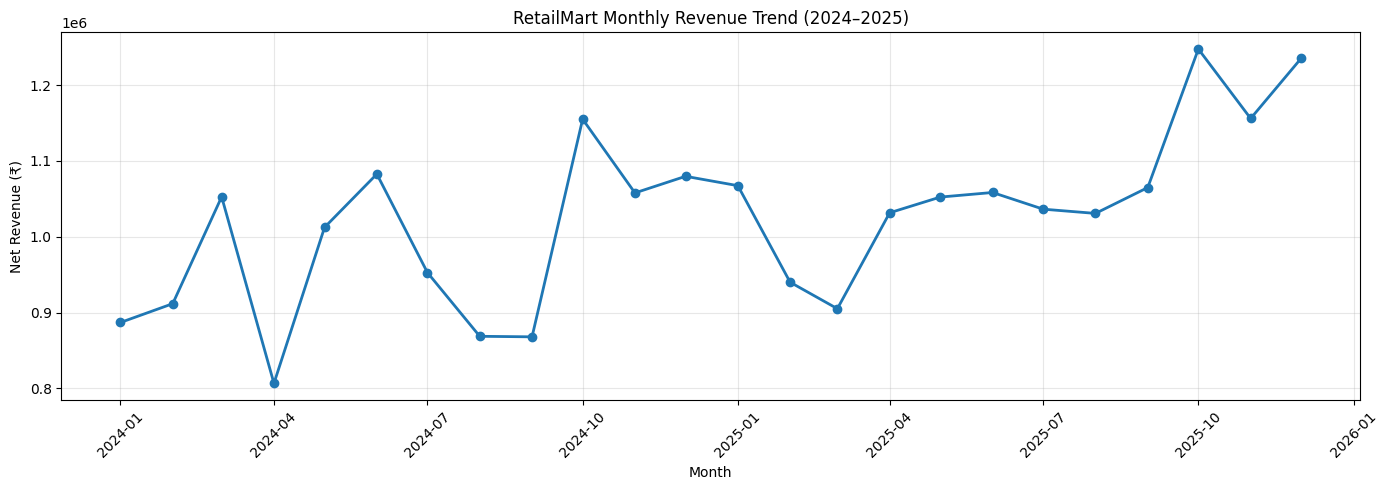

,Sales_Month,Total_Revenue,Transactions
0,2024-01-01,8.869715e+05,336
1,2024-02-01,9.117699e+05,369
2,2024-03-01,1.052568e+06,393
3,2024-04-01,8.067432e+05,344
4,2024-05-01,1.012345e+06,419
5,2024-06-01,1.082623e+06,397
6,2024-07-01,9.527332e+05,362
7,2024-08-01,8.687666e+05,384
8,2024-09-01,8.680690e+05,360
9,2024-10-01,1.154968e+06,449


In [ ]:

monthly_revenue = (
    sales_eda.groupby("Sales_Month", as_index=False)
    .agg(
        Total_Revenue=("Net_Revenue", "sum"),
        Transactions=("Net_Revenue", "count")
    )
    .sort_values("Sales_Month")
)

monthly_revenue["Sales_Month"] = pd.to_datetime(
    monthly_revenue["Sales_Month"],
    format="%Y-%m"
)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_revenue["Sales_Month"],
    monthly_revenue["Total_Revenue"],
    marker="o",
    linewidth=2
)

plt.title("RetailMart Monthly Revenue Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Net Revenue (₹)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_revenue)


,Category,Total_Revenue,Gross_Profit,Units_Sold,Profit_Margin_Pct
2,Electronics,8755784.46,3410830.96,2163,38.96
3,Home & Kitchen,4504568.25,1384481.87,3139,30.74
4,Sports & Outdoors,4029921.49,1391608.31,2836,34.53
0,Beauty,3365809.38,1384743.39,3012,41.14
1,Clothing,3193250.39,1380005.04,2723,43.22
7,electronics,322473.01,71410.82,127,22.14
8,home & kitchen,202364.37,99530.66,179,49.18
6,clothing,141580.37,58797.88,61,41.53
5,beauty,44392.38,19051.26,112,42.92


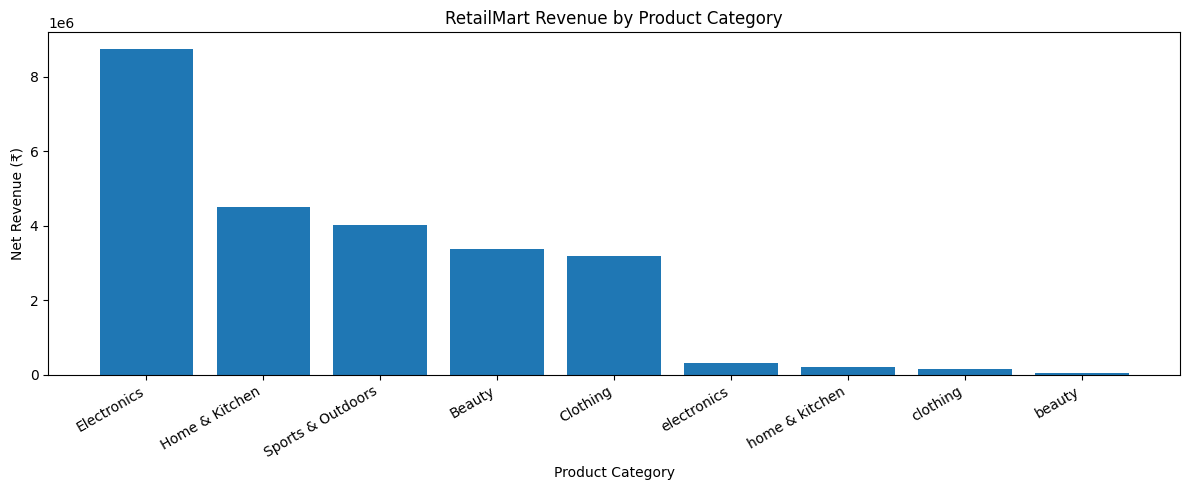

In [ ]:

category_analysis = (
    sales_eda[sales_eda["Net_Revenue"].notna()]
    .assign(
        Gross_Profit=lambda df: df["Net_Revenue"] - df["Net_Cost"]
    )
    .groupby("Category", as_index=False)
    .agg(
        Total_Revenue=("Net_Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum"),
        Units_Sold=("Net_Quantity", "sum")
    )
)

category_analysis["Profit_Margin_Pct"] = (
    category_analysis["Gross_Profit"]
    / category_analysis["Total_Revenue"]
    * 100
).round(2)

category_analysis = category_analysis.sort_values(
    "Total_Revenue", ascending=False
)

display(category_analysis.round(2))

plt.figure(figsize=(12, 5))

plt.bar(
    category_analysis["Category"],
    category_analysis["Total_Revenue"]
)

plt.title("RetailMart Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Net Revenue (₹)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


TOP 10 PRODUCTS BY REVENUE


,Product_ID,Product_Name,Total_Revenue,Units_Sold,Gross_Profit
7,P008,Monitor,2191666.22,202,1116557.58
55,P056,Tennis Racket,1995837.59,924,688359.11
3,P004,Speaker,1584452.56,222,445321.72
29,P030,Bedsheet,899583.99,432,299453.91
8,P009,USB Hub,869288.50,99,292728.34
25,P026,Blender,867899.25,371,354639.30
4,P005,Webcam,846548.80,455,311082.05
52,P053,Water Flask,816262.16,413,317502.71
10,P011,Router,780782.72,313,176536.22
20,P021,Shorts,770369.89,273,387880.51


TOP 10 PRODUCTS BY QUANTITY SOLD


,Product_ID,Product_Name,Total_Revenue,Units_Sold,Gross_Profit
55,P056,Tennis Racket,1995837.59,924,688359.11
34,P035,Wall Clock,615446.75,595,106019.65
36,P037,Shampoo,249556.74,468,79480.86
4,P005,Webcam,846548.80,455,311082.05
56,P057,Camping Light,215497.27,451,71822.20
29,P030,Bedsheet,899583.99,432,299453.91
23,P024,Scarf,751544.09,428,252748.61
47,P048,Deodorant,298823.80,423,140727.55
18,P019,Socks,398609.59,419,159825.68
52,P053,Water Flask,816262.16,413,317502.71


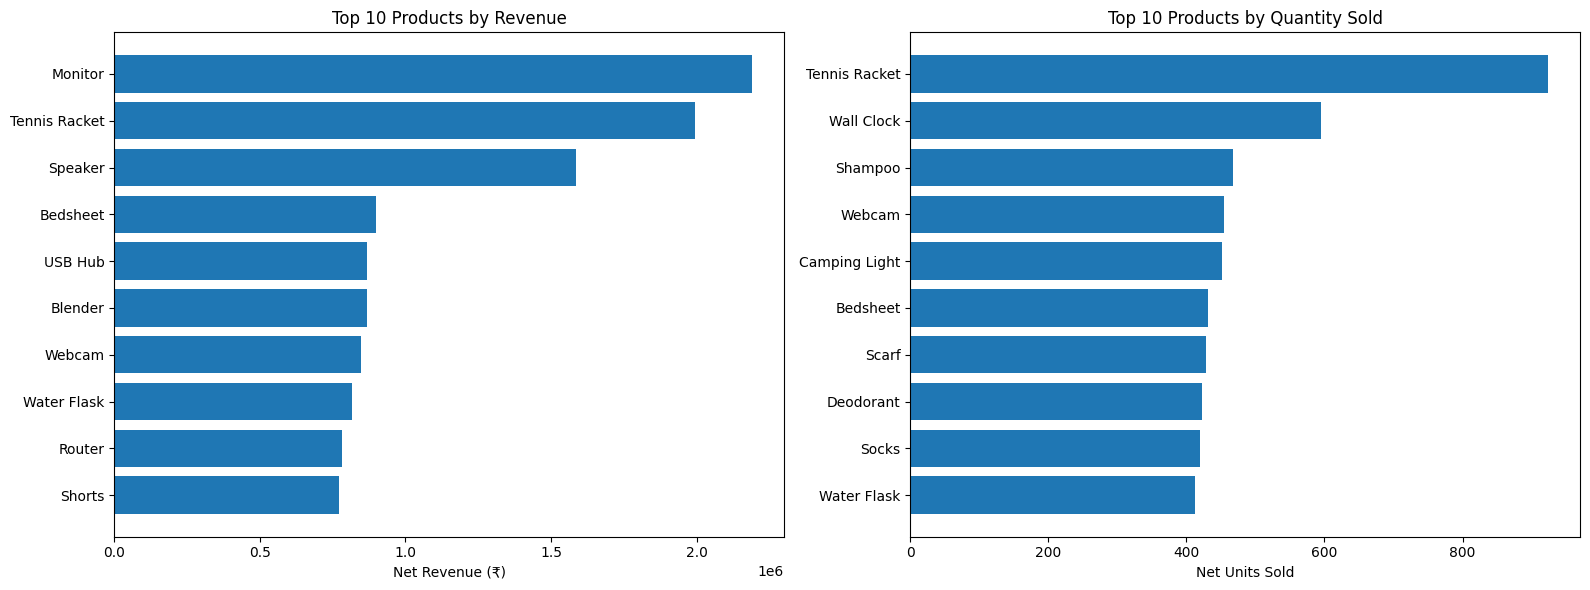

In [ ]:

product_analysis = (
    sales_eda[sales_eda["Net_Revenue"].notna()]
    .assign(
        Gross_Profit=lambda df: df["Net_Revenue"] - df["Net_Cost"]
    )
    .groupby(["Product_ID", "Product_Name"], as_index=False)
    .agg(
        Total_Revenue=("Net_Revenue", "sum"),
        Units_Sold=("Net_Quantity", "sum"),
        Gross_Profit=("Gross_Profit", "sum")
    )
)

top_revenue = product_analysis.nlargest(10, "Total_Revenue")
top_quantity = product_analysis.nlargest(10, "Units_Sold")

print("TOP 10 PRODUCTS BY REVENUE")
display(top_revenue.round(2))

print("TOP 10 PRODUCTS BY QUANTITY SOLD")
display(top_quantity.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(
    top_revenue["Product_Name"][::-1],
    top_revenue["Total_Revenue"][::-1]
)
axes[0].set_title("Top 10 Products by Revenue")
axes[0].set_xlabel("Net Revenue (₹)")

axes[1].barh(
    top_quantity["Product_Name"][::-1],
    top_quantity["Units_Sold"][::-1]
)
axes[1].set_title("Top 10 Products by Quantity Sold")
axes[1].set_xlabel("Net Units Sold")

plt.tight_layout()
plt.show()


STORE-WISE PERFORMANCE


,Store_ID,Store_Name,City,Region,Total_Revenue,Gross_Profit,Units_Sold,Total_Orders,Profit_Margin_Pct
0,S01,RetailMart T Nagar,Chennai,South,5864702.15,2205686.19,3262,1763,37.61
1,S02,RetailMart RS Puram,Coimbatore,South,4556073.92,1698225.23,2687,1514,37.27
2,S03,RetailMart Indiranagar,Bengaluru,south,4328106.53,1599431.43,2592,1429,36.95
3,S04,RetailMart Andheri,Mumbai,West,4101538.67,1556626.65,2387,1347,37.95
4,S05,RetailMart Connaught Place,New Delhi,North,3239645.73,1227992.18,1861,1027,37.91
5,S06,RetailMart Salt Lake,Kolkata,East,2470077.10,912498.51,1563,856,36.94


REGION-WISE PERFORMANCE


,Region,Total_Revenue,Gross_Profit,Profit_Margin_Pct
2,South,10420776.08,3903911.43,37.46
4,south,4328106.53,1599431.43,36.95
3,West,4101538.67,1556626.65,37.95
1,North,3239645.73,1227992.18,37.91
0,East,2470077.10,912498.51,36.94


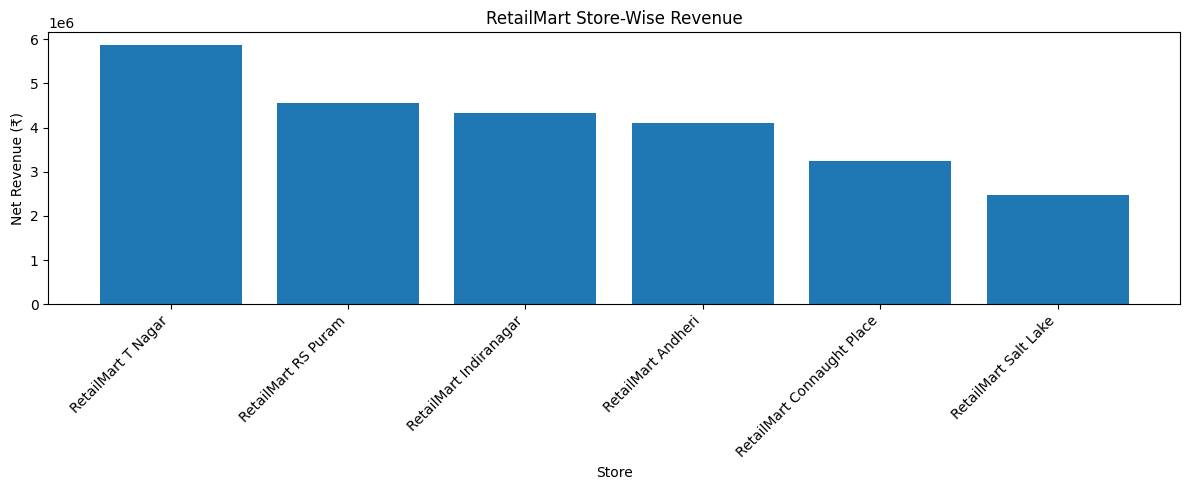

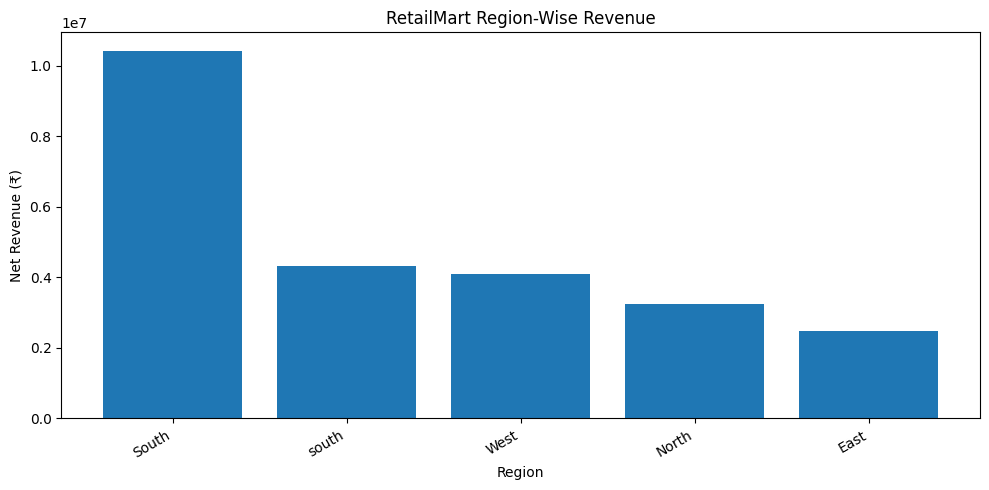

In [ ]:

store_analysis = (
    sales_eda[sales_eda["Net_Revenue"].notna()]
    .assign(
        Gross_Profit=lambda df: df["Net_Revenue"] - df["Net_Cost"]
    )
    .groupby(["Store_ID", "Store_Name", "City", "Region"], as_index=False)
    .agg(
        Total_Revenue=("Net_Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum"),
        Units_Sold=("Net_Quantity", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
)

store_analysis["Profit_Margin_Pct"] = (
    store_analysis["Gross_Profit"]
    / store_analysis["Total_Revenue"]
    * 100
).round(2)

store_analysis = store_analysis.sort_values(
    "Total_Revenue", ascending=False
)

print("STORE-WISE PERFORMANCE")
display(store_analysis.round(2))

region_analysis = (
    store_analysis.groupby("Region", as_index=False)
    .agg(
        Total_Revenue=("Total_Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum")
    )
)

region_analysis["Profit_Margin_Pct"] = (
    100 * region_analysis["Gross_Profit"]
    / region_analysis["Total_Revenue"]
).round(2)

region_analysis = region_analysis.sort_values(
    "Total_Revenue", ascending=False
)

print("REGION-WISE PERFORMANCE")
display(region_analysis.round(2))

plt.figure(figsize=(12, 5))

plt.bar(
    store_analysis["Store_Name"],
    store_analysis["Total_Revenue"]
)

plt.title("RetailMart Store-Wise Revenue")
plt.xlabel("Store")
plt.ylabel("Net Revenue (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.bar(
    region_analysis["Region"],
    region_analysis["Total_Revenue"]
)

plt.title("RetailMart Region-Wise Revenue")
plt.xlabel("Region")
plt.ylabel("Net Revenue (₹)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


CUSTOMER SEGMENT PERFORMANCE


,Customer_Segment,Total_Revenue,Total_Orders,Total_Transactions,Units_Sold,Average_Order_Value,Revenue_Share_Pct
3,Regular,11733534.32,3786,4725,6785,3099.19,47.77
0,Loyal,5614973.64,1846,2294,3312,3041.70,22.86
1,New,4823142.16,1529,1943,2830,3154.44,19.64
2,Premium,2015077.28,653,794,1176,3085.88,8.20
4,Unknown,373416.71,145,167,249,2575.29,1.52


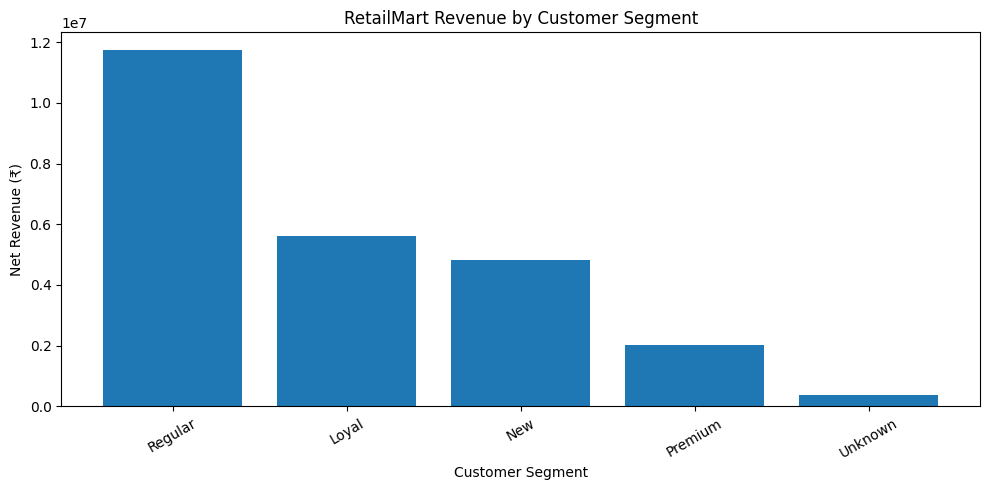

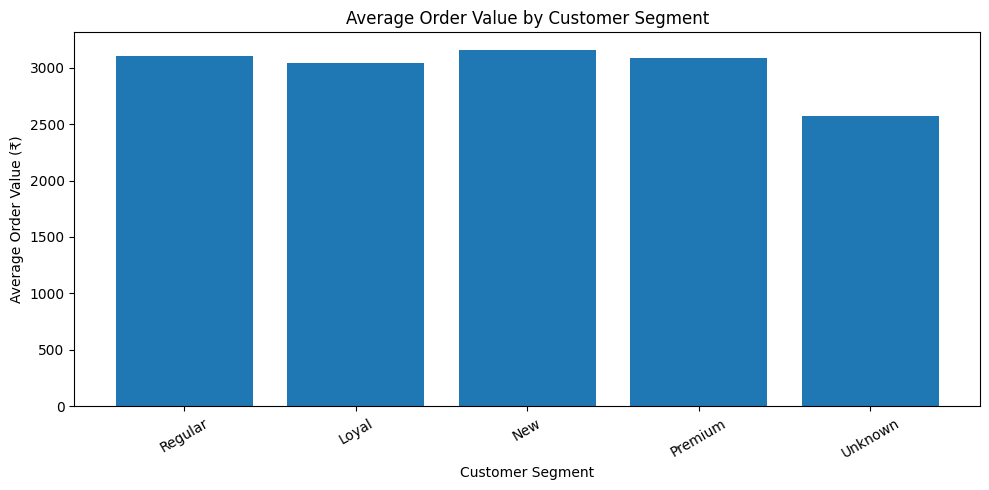

In [ ]:

customer_analysis = (
    sales_eda[sales_eda["Net_Revenue"].notna()]
    .assign(
        Customer_Segment=lambda df: df["Customer_Segment"].fillna("Unknown")
    )
    .groupby("Customer_Segment", as_index=False)
    .agg(
        Total_Revenue=("Net_Revenue", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Total_Transactions=("Transaction_ID", "count"),
        Units_Sold=("Net_Quantity", "sum")
    )
)

customer_analysis["Average_Order_Value"] = (
    customer_analysis["Total_Revenue"]
    / customer_analysis["Total_Orders"]
).round(2)

customer_analysis["Revenue_Share_Pct"] = (
    customer_analysis["Total_Revenue"]
    / customer_analysis["Total_Revenue"].sum()
    * 100
).round(2)

customer_analysis = customer_analysis.sort_values(
    "Total_Revenue", ascending=False
)

print("CUSTOMER SEGMENT PERFORMANCE")
display(customer_analysis.round(2))

plt.figure(figsize=(10, 5))

plt.bar(
    customer_analysis["Customer_Segment"],
    customer_analysis["Total_Revenue"]
)

plt.title("RetailMart Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Net Revenue (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.bar(
    customer_analysis["Customer_Segment"],
    customer_analysis["Average_Order_Value"]
)

plt.title("Average Order Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Order Value (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,Inventory_Month,Opening_Stock,Stock_Received,Units_Sold,Stockout_Records,Inventory_Observations,Average_Closing_Value,Stockout_Rate_Pct
0,2024-01,135098.0,1465.0,138.0,10,3224,49039.55,0.31
1,2024-02,133594.0,357.0,177.0,0,3015,53636.52,0.00
2,2024-03,150025.0,436.0,222.0,0,3224,55829.94,0.00
3,2024-04,148245.0,357.0,174.0,0,3117,55837.56,0.00
4,2024-05,160284.0,313.0,222.0,0,3223,59279.93,0.00
5,2024-06,157920.0,535.0,217.0,0,3119,60032.54,0.00
6,2024-07,171272.0,323.0,220.0,0,3224,61934.35,0.00
7,2024-08,175434.0,504.0,212.0,0,3224,63398.98,0.00
8,2024-09,175177.0,154.0,237.0,0,3120,67248.71,0.00
9,2024-10,179495.0,311.0,246.0,0,3223,67453.90,0.00


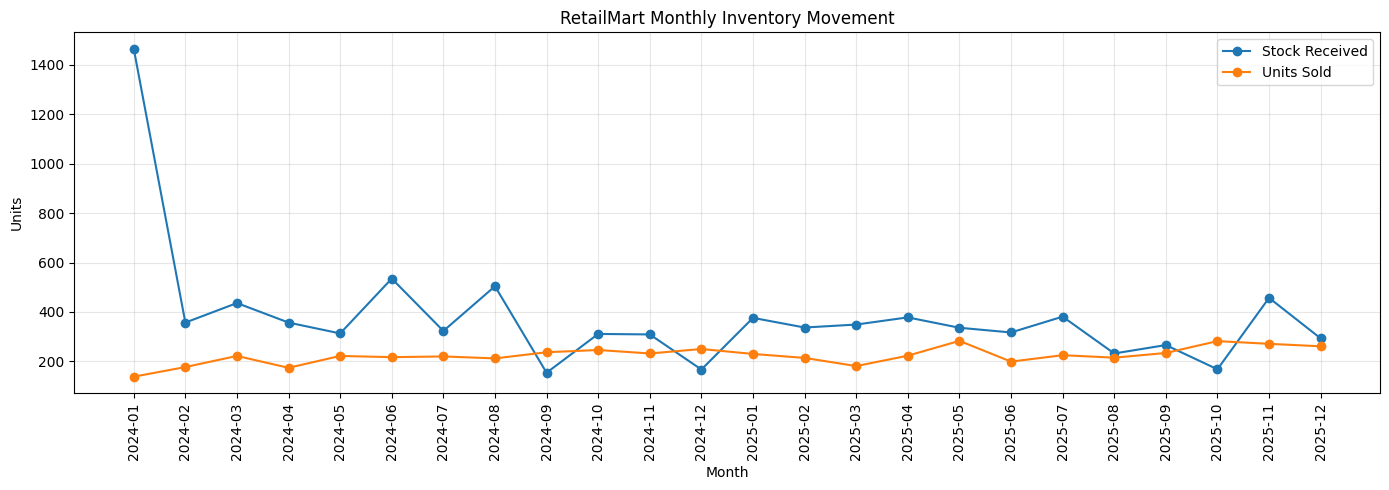

PRODUCTS WITH HIGHEST STOCKOUT FREQUENCY


,Product_ID,Product_Name,Stockout_Days,Inventory_Observations,Average_Closing_Stock,Stockout_Rate_Pct
49,P050,Dumbbells,1,731,69.29,0.14
52,P053,Water Flask,1,730,52.30,0.14
58,P059,Sports Towel,1,731,65.70,0.14
43,P044,Serum,1,1117,53.09,0.09
15,P016,Hoodie,1,1459,69.04,0.07
3,P004,Speaker,1,1462,39.12,0.07
4,P005,Webcam,1,1462,57.95,0.07
6,P007,Power Bank,1,1462,34.89,0.07
30,P031,Pillow,1,1462,76.04,0.07
35,P036,Towel,1,1461,36.80,0.07


In [ ]:

inventory_analysis = inventory_eda.copy()

inventory_analysis["Inventory_Month"] = inventory_analysis["Date"].dt.to_period("M").astype(str)

monthly_inventory = (
    inventory_analysis.groupby("Inventory_Month", as_index=False)
    .agg(
        Opening_Stock=("Opening_Stock", "sum"),
        Stock_Received=("Stock_Received", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Stockout_Records=("Stockout_Flag", "sum"),
        Inventory_Observations=("Stockout_Flag", "count"),
        Average_Closing_Value=("Closing_Inventory_Value", "mean")
    )
)

monthly_inventory["Stockout_Rate_Pct"] = (
    100 * monthly_inventory["Stockout_Records"]
    / monthly_inventory["Inventory_Observations"]
).round(3)

display(monthly_inventory.round(2))

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_inventory["Inventory_Month"],
    monthly_inventory["Stock_Received"],
    marker="o",
    label="Stock Received"
)

plt.plot(
    monthly_inventory["Inventory_Month"],
    monthly_inventory["Units_Sold"],
    marker="o",
    label="Units Sold"
)

plt.title("RetailMart Monthly Inventory Movement")
plt.xlabel("Month")
plt.ylabel("Units")
plt.xticks(rotation=90)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

product_inventory = (
    inventory_analysis.groupby(
        ["Product_ID", "Product_Name"], as_index=False
    )
    .agg(
        Stockout_Days=("Stockout_Flag", "sum"),
        Inventory_Observations=("Stockout_Flag", "count"),
        Average_Closing_Stock=("Closing_Stock", "mean")
    )
)

product_inventory["Stockout_Rate_Pct"] = (
    100 * product_inventory["Stockout_Days"]
    / product_inventory["Inventory_Observations"]
).round(3)

product_inventory = product_inventory.sort_values(
    ["Stockout_Days", "Stockout_Rate_Pct"],
    ascending=False
)

print("PRODUCTS WITH HIGHEST STOCKOUT FREQUENCY")
display(product_inventory.head(10).round(2))

**Validate and Export EDA Results**

In [ ]:

import os
import shutil
from google.colab import files

os.makedirs("RetailMart_PowerBI_Data", exist_ok=True)

print("FINAL EDA VALIDATION")

print("Sales Records:", len(sales_eda))
print("Inventory Records:", len(inventory_eda))
print("Missing Revenue:", sales_eda["Net_Revenue"].isna().sum())

print("Total Revenue:", round(sales_eda["Net_Revenue"].sum(), 2))

valid_sales = sales_eda[sales_eda["Net_Revenue"].notna()]

gross_profit = (
    valid_sales["Net_Revenue"] - valid_sales["Net_Cost"]
).sum()

print("Gross Profit:", round(gross_profit, 2))

exports = {
    "Sales_Analysis.csv": sales_eda,
    "Inventory_Analysis.csv": inventory_eda,
    "Monthly_Revenue.csv": monthly_revenue,
    "Category_Analysis.csv": category_analysis,
    "Product_Analysis.csv": product_analysis,
    "Store_Analysis.csv": store_analysis,
    "Region_Analysis.csv": region_analysis,
    "Customer_Analysis.csv": customer_analysis,
    "Monthly_Inventory.csv": monthly_inventory,
    "Product_Inventory.csv": product_inventory
}

for filename, df in exports.items():
    df.to_csv(
        f"RetailMart_PowerBI_Data/{filename}",
        index=False
    )
    print(filename, "Exported")

shutil.make_archive(
    "RetailMart_PowerBI_Data",
    "zip",
    "RetailMart_PowerBI_Data"
)

files.download("RetailMart_PowerBI_Data.zip")


FINAL EDA VALIDATION
Sales Records: 9970
Inventory Records: 75656
Missing Revenue: 47
Total Revenue: 24560144.11
Gross Profit: 9200460.2
Sales_Analysis.csv Exported
Inventory_Analysis.csv Exported
Monthly_Revenue.csv Exported
Category_Analysis.csv Exported
Product_Analysis.csv Exported
Store_Analysis.csv Exported
Region_Analysis.csv Exported
Customer_Analysis.csv Exported
Monthly_Inventory.csv Exported
Product_Inventory.csv Exported


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>